# Lab 9: Report

## Three-Point Bending Test of Glass

The main objective of this lab is to understand the testing methods and related challenges for determining the mechanical properties of brittle materials, such as glasses and ceramics.

Recommended reading: Calister, *Materials Science and Engineering: An Introduction*, Chapter 12.8-12.9

## 1. Import data into the notebook

### 1.1 Definitions

- Import necessary libraries
- define the span used for the 3-point bend test in millimeters

In [63]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# define the span used to collect the data in meters
SPAN_MM = 50.8 # millimeters


### 1.2 Import the important data

The data from each lab section has  been compiled into a single .csv file to allow statistical analysis. Import the .csv data file as a pandas dataframe.

- skip the first row
- only import the columns you need
- define the column names during the import

In [64]:
#import the data from the csv. Ignore the first column
df = pd.read_csv('GlassFractureDataCleaned.csv',
                 skiprows=1,
                 usecols=[1,2,4],
                 names=["Label", "Dia / mm", "Load / N"])

# normalize all Labels to lowercase to make case-insensitive

df["Label"] = df["Label"].str.lower()

df.head()

,Label,Dia / mm,Load / N
0,uncoated,8.001,799.490
1,uncoated,8.001,664.500
2,uncoated,8.077,644.134
3,uncoated,8.052,862.570
4,uncoated,4.166,94.278


## 2. Group the data and calculate stress

Prepare the data for plotting and statistical analysis.


### 2.1 Group the data

Each sample must be split up according to the group it belongs to based on:
1. Coating
1. Diameter

The code below specifies the condition each sample must meet to be part of the same group. Each sample is assigned a group number **1** through **4**.

**note**: If a sample can't be identified it gets assigned to group **0**.

In [65]:
conditions = [
    (df['Label'] == 'uncoated') & (df['Dia / mm'] >= 3) & (df['Dia / mm'] <= 5),
    (df['Label'] == 'coated') & (df['Dia / mm'] >= 3) & (df['Dia / mm'] <= 5),
    (df['Label'] == 'uncoated') & (df['Dia / mm'] >= 7) & (df['Dia / mm'] <= 9),
    (df['Label'] == 'coated') & (df['Dia / mm'] >= 7) & (df['Dia / mm'] <= 9)
]

df['group'] = np.select(condlist = conditions, choicelist = [1, 2, 3, 4], default=0)
for i in np.unique(df["group"]):
    group_count = (df["group"] == i).sum()
    print(f"Group {i}, {group_count} entries:")
    display(df[df['group'] == i].head(5))


Group 0, 4 entries:


,Label,Dia / mm,Load / N,group
69,uncoated,6.502,83.602,0
185,uncoated 1,7.925,740.157,0
200,coated samples,8.052,646.062,0
237,NaN,4.064,28.665,0


Group 1, 121 entries:


,Label,Dia / mm,Load / N,group
4,uncoated,4.166,94.278,1
5,uncoated,4.166,101.703,1
6,uncoated,4.293,75.192,1
7,uncoated,4.191,77.820,1
8,uncoated,4.242,147.339,1


Group 2, 123 entries:


,Label,Dia / mm,Load / N,group
21,coated,4.166,105.373,2
22,coated,4.064,113.976,2
23,coated,4.140,103.370,2
24,coated,4.039,96.930,2
25,coated,3.962,62.185,2


Group 3, 124 entries:


,Label,Dia / mm,Load / N,group
0,uncoated,8.001,799.490,3
1,uncoated,8.001,664.500,3
2,uncoated,8.077,644.134,3
3,uncoated,8.052,862.570,3
13,uncoated,8.001,692.313,3


Group 4, 125 entries:


,Label,Dia / mm,Load / N,group
17,coated,8.001,561.643,4
18,coated,8.052,480.128,4
19,coated,8.001,1035.530,4
20,coated,8.052,558.478,4
28,coated,8.026,785.427,4


`Engineering Check`:

If any samples are in group 0, find them in the `.csv` file edit them so they can be properly assigned. 

Alternatively, drop the group 0 entries with your choice of the code below. Uncomment lines and edit as desired.

In [66]:
# OPTIONAL: Drop any entries that can't be reconciled into groups 1 through 4

#df = df[df['group'] != 0].copy()  # uncomment to drop all group 0 entries

#df = df.drop(index=n)  # uncomment and replace "n" with the index of the entry to be dropped

### 2.2 Calculations

The glass rods were loaded into a 3-point bend test and loaded until fracture. Write the equation below used to caculate maximum tensile stress in the glass rod based on the load applied and the specimen geometry. Define the variables used

$$\sigma_\mathrm{fs}=...$$

$\sigma_\mathrm{fs}$: Bending Stress / Pa

In the code cell below calculate the flexural strength in MPa. Round to appropriate significant figures.

**Functions for your code**:

- `.round(n)`: round to n decimal places
- `**n`: two multiplication signs raise to the power of n

**Variables for your code**:

- `df['Load / N']`: Load at fracture
- `df['Dia / mm']`: Specimen diameter in millimeters
- `SPAN_MM`: Span length of test frame in meters

In [67]:
df['Flex Strength / MPa'] = df['Load / N'] * SPAN_MM / (np.pi * (df['Dia / mm']/2)**3 )
df['Flex Strength / MPa'] = df['Flex Strength / MPa'].round(1)

df.head()   # display the first few lines of the dataframe after calculating flexural strength

,Label,Dia / mm,Load / N,group,Flex Strength / MPa
0,uncoated,8.001,799.490,3,201.9
1,uncoated,8.001,664.500,3,167.8
2,uncoated,8.077,644.134,3,158.1
3,uncoated,8.052,862.570,3,213.7
4,uncoated,4.166,94.278,1,168.7


`Engineering Check`:

Compare your calculated values of flexural strength with accepted values. Are you in the correct range?

## 3. Generating Figures

### 3.1 Distribution of failed specimens as a function of flexural strength (20 points) 

Use a histogram to plot the number of failed samples as a function of flexural strength for all four groups

1. Define `STEP`: the width in MPa of each bin for the historgram
1. Define `STRESS_MIN` and `STRESS_MAX`: Stress cutoffs for the data
1. Select which plotting option displays the data best (delete the other code) and explain
1. Label the axes
1. Provide a descriptive figure caption

In [68]:
STEP = 20 # Step Size MPa
STRESS_MIN = 50 # Minimum MPa
STRESS_MAX = 330 # MPa

# store a mask of the values which are within the user defined stress limits
in_range = (df["Flex Strength / MPa"] >= STRESS_MIN) & (df["Flex Strength / MPa"] <= STRESS_MAX)
ignored = ~in_range & (df["group"] != 0)


BINS = np.arange(STRESS_MIN, STRESS_MAX, STEP)

# names of each group from 1 to 4
group_names = {1: 'Uncoated, Diameter 3-5 mm',
          2: 'Coated, Diameter 3-5 mm',
          3: 'Uncoated, Diameter 7-9 mm',
          4: 'Coated, Diameter 7-9 mm'}

# print out which specimen data are being ignored
print(f"Ignored {ignored.sum()} specimen outside {STRESS_MIN}–{STRESS_MAX} MPa:")
print(df.loc[ignored, ["group", "Flex Strength / MPa"]])
    

Ignored 2 specimen outside 50–330 MPa:
     group  Flex Strength / MPa
245      1                462.1
325      3                 39.3


#### Option 1: Four subplots

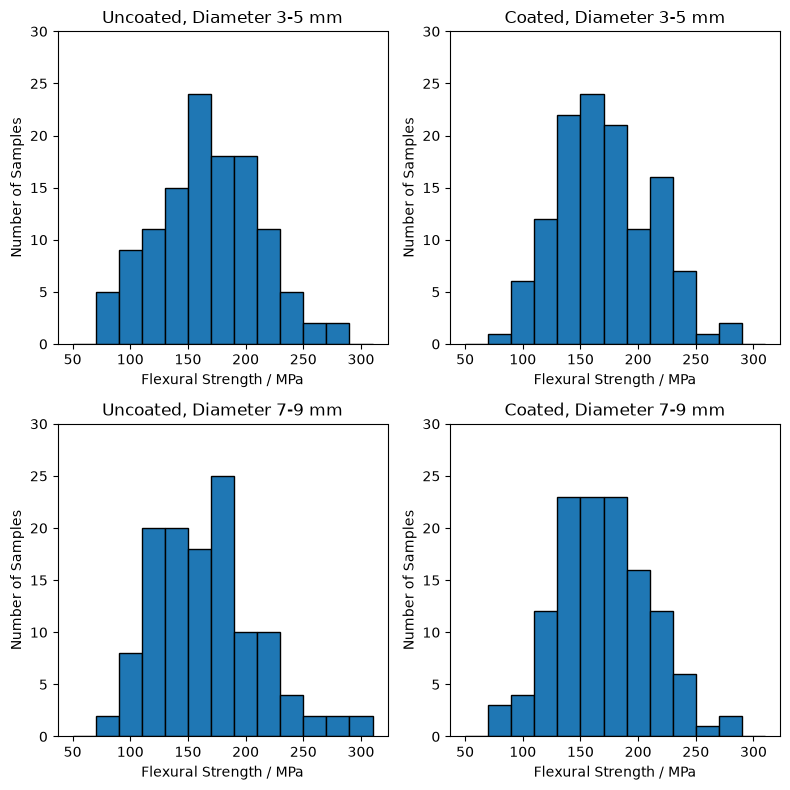

Figure 1. DESCRIPTIVE CAPTION HERE


In [69]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for ax, key in zip(axes.ravel(), group_names.keys()):

    #select the data for each group
    group_data = df[df['group'] == key]['Flex Strength / MPa']

    #plot each groups data in a histogram
    counts, bin_edges, patches = ax.hist(group_data, bins=BINS, label=group_names[key], edgecolor='black')
    ax.set_title(group_names[key])
    ax.set_xlabel('Flexural Strength / MPa')
    ax.set_ylabel('Number of Samples')
    ax.set_ylim([0, 30])  #set a consistent y-axis for comparison



plt.tight_layout()
plt.show()

# STUDENT: add a descriptive figure caption. Explain the trends in the caption.
print("Figure 1. DESCRIPTIVE CAPTION HERE")

#### Option 2: A single stacked plot

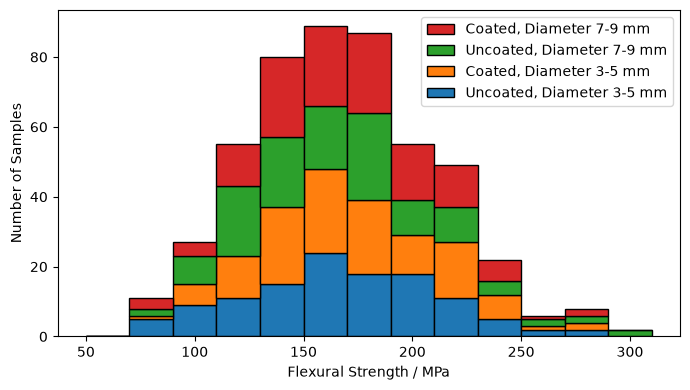

Figure 1. DESCRIPTIVE CAPTION HERE


In [70]:
fig, ax = plt.subplots(figsize=(7, 4))

# collect each group's data into a list
data = [df[df['group'] == key]['Flex Strength / MPa'] for key in group_names.keys()]

# one hist call with all groups -> stacked
ax.hist(data, bins=BINS, stacked=True, label=list(group_names.values()), edgecolor='black')

ax.set_xlabel('Flexural Strength / MPa')
ax.set_ylabel('Number of Samples')

# these two lines align the order of the legend with the bar plot
handles, labels = ax.get_legend_handles_labels() # get the legend information
ax.legend(handles[::-1], labels[::-1]) # flip the order of the handles and labels

plt.tight_layout()
plt.show()

print("Figure 1. DESCRIPTIVE CAPTION HERE")

After the plotting is complete, drop any values from the dataframe which were out of the plotting bounds using the `ignored` mask generated earlier. This eliminates them from further analysis.

In [71]:
# Run this cell to drop all the ignored data from future plotting and statistics

df = df[~ignored]

**`YOUR RESPONSE`**

Explain why you selected plotting option 1 or 2. How does it more clearly convey the important information?

### 3.2 Plot the cumulative probability of failure (20 points)

Plot the cumulative probability that a specimen has failed  as a function of flexural strength for the combined data $P\left(  \sigma_\mathrm{fs}  \right)$.

To determine the probability of failure, sort the specimens in ascending order of flexural strength, then determine the probability of failure defined as
$$P\left(  \sigma_\mathrm{fs}  \right) = \frac{n}{N+1}$$
where $n$ is the number of failed samples for a given stress and $N$ is the total number of samples.

**Functions for your code**:

- `np.arange(start, stop)`: creates an array containing values from `start` to `stop`, spaced 1 apart by default 
- `df.sort_values("column name")`: sorts the dataframe `df` by the values in `"column name"` (ascending by default)
- `len(df)`: returns the number of items in the dataframe `df`


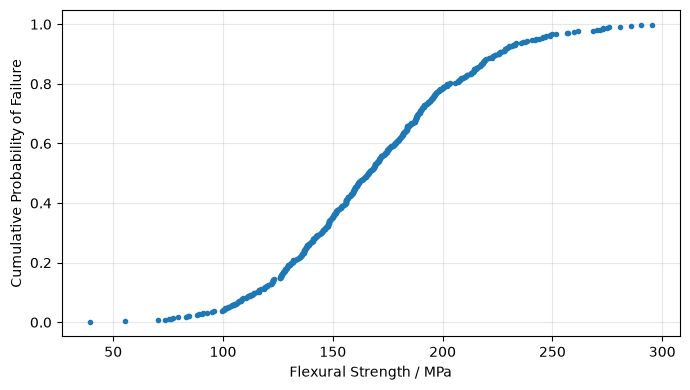

Figure 2. YOUR RESPONSE


In [75]:
df = df.sort_values("Flex Strength / MPa")

N = len(df)
n = np.arange(1, N + 1)
probability = n / (N + 1)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(df["Flex Strength / MPa"], probability, marker=".", linestyle="none")
ax.set_xlabel("Flexural Strength / MPa")
ax.set_ylabel(r"Cumulative Probability of Failure")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Figure 2. YOUR RESPONSE")

## 4. Statistics (10 points)

**`YOUR RESPONSE`**

Determine and list the numer of specimens, mean, median, and standard deviation of the observed flexural strength values for each group and for the lumped dataset.

**Variables for your code**:

- `strengths`: flexural strength for the selected subset of specimens

**Functions for your code**:

- `.count()`: Returns the number of observations / samples
- `.mean()`: Returns the mean
- `.median()`: Returns the median
- `.std()`: Returns the standard deviation

In [ ]:
results = []

for group, title in group_names.items():

    # flexural strengths of each group
    strengths = df.loc[df["group"] == group, "Flex Strength / MPa"]

    # add the statistics for each group to the dataframe
    results.append({
        "Group": title,
        "Count": strengths.count(),
        "Mean / MPa": strengths.mean(),
        "Median / MPa": strengths.median(),
        "Standard deviation / MPa": strengths.std()
    })


# flexural strengths for the lumped dataset
strengths = df["Flex Strength / MPa"]

# add the statistics for the lumped dataset to the dataframe
results.append({
    "Group": "Entire dataset",
    "Count": strengths.count(),
    "Mean / MPa": strengths.mean(),
    "Median / MPa": strengths.median(),
    "Standard deviation / MPa": strengths.std()
})

#print out the statistics results
stats_df = pd.DataFrame(results).round(1)
print(stats_df.to_string(index=False))

69      39.3
237     55.2
135     70.5
311     73.8
447     75.3
       ...  
401    275.8
190    280.7
255    285.6
468    290.2
14     295.3
Name: Flex Strength / MPa, Length: 495, dtype: float64
                    Group  Count  Mean / MPa  Median / MPa  Standard deviation / MPa
Uncoated, Diameter 3-5 mm    120       167.5         168.4                      43.9
  Coated, Diameter 3-5 mm    123       171.3         166.2                      40.8
Uncoated, Diameter 7-9 mm    123       166.2         163.8                      44.7
  Coated, Diameter 7-9 mm    125       169.9         166.8                      40.2
           Entire dataset    495       168.3         166.2                      42.9


## 5. Effect of coating (10 points)

**`YOUR RESPONSE`**

Does coating the specimens with a layer of nail polis have an effect on the stress distribution? If so, explain the physical mechanism resulting in the difference.

*YOUR RESPONSE HERE*

## 6. Fracture Surfaces (15 points)

**`YOUR RESPONSE`**

Describe in words and show the most prominent features of the fracture surface. Refer to specific features in your micrograph(s).

*YOUR RESPONSE HERE*

In [ ]:
# Include the relevant micrographs here.

# Basic code for displaying an image
micrograph_image = plt.imread("image_file.jpg") # replace image_file.jpg with the correct file

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.imshow(micrograph_image)
ax.set_title("YOUR RESPONSE")
ax.axis("off")

plt.tight_layout()
plt.show()

# provide a descriptive caption
print("Figure X. YOUR RESPONSE")

## CONTRIBUTION STATEMENT

**`YOUR RESPONSE`**

*List each contributor and what they did.*

| Contributor | Contribution |
|:---|:---|
| YOUR NAME | YOUR CONTRIBUTION |
| YOUR NAME | YOUR CONTRIBUTION |
| YOUR NAME | YOUR CONTRIBUTION |
| YOUR NAME | YOUR CONTRIBUTION |
| YOUR NAME | YOUR CONTRIBUTION |

## SUBMISSION

When this notebook is complete and ready to submit, export it as a PDF file. If the PDF compile fails check your $\LaTeX$ code for errors.